In [ ]:
# B2B Sales Pipeline Analysis

## Project Overview

This project analyzes B2B sales data to understand revenue, sales performance, deal conversion, and pipeline performance.

## Objectives

- Analyze sales opportunities.
- Calculate the overall win rate.
- Identify top-performing products.
- Evaluate sales agent performance.
- Understand sales pipeline distribution.
    

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
df = pd.read_excel("b2b_sales_data.xlsx", sheet_name="b2b_sales_data")


In [5]:
df.head()


,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,1054.0
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,4514.0
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.0
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.0
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.0


In [6]:
df.tail()

,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value
8795,9MIWFW5J,Versie Hillebrand,MG Advanced,NaN,Prospecting,NaT,NaT,NaN
8796,6SLKZ8FI,Versie Hillebrand,MG Advanced,NaN,Prospecting,NaT,NaT,NaN
8797,LIB4KUZJ,Versie Hillebrand,MG Advanced,NaN,Prospecting,NaT,NaT,NaN
8798,18IUIUK0,Versie Hillebrand,MG Advanced,NaN,Prospecting,NaT,NaT,NaN
8799,8I5ONXJX,Versie Hillebrand,MG Advanced,NaN,Prospecting,NaT,NaT,NaN


In [7]:
df.shape

(8800, 8)

In [8]:
df.columns

Index(['opportunity_id', 'sales_agent', 'product', 'account', 'deal_stage',
       'engage_date', 'close_date', 'close_value'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8800 entries, 0 to 8799
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   opportunity_id  8800 non-null   object        
 1   sales_agent     8800 non-null   object        
 2   product         8800 non-null   object        
 3   account         7375 non-null   object        
 4   deal_stage      8800 non-null   object        
 5   engage_date     8300 non-null   datetime64[ns]
 6   close_date      6711 non-null   datetime64[ns]
 7   close_value     6711 non-null   float64       
dtypes: datetime64[ns](2), float64(1), object(5)
memory usage: 550.1+ KB


In [10]:
df.describe()

,engage_date,close_date,close_value
count,8300,6711,6711.000000
mean,2017-06-14 08:35:06.216867584,2017-08-01 03:32:25.641484032,1490.915512
min,2016-10-20 00:00:00,2017-03-01 00:00:00,0.000000
25%,2017-04-04 00:00:00,2017-05-18 00:00:00,0.000000
50%,2017-06-24 00:00:00,2017-08-02 00:00:00,472.000000
75%,2017-08-27 00:00:00,2017-10-18 00:00:00,3225.000000
max,2017-12-27 00:00:00,2017-12-31 00:00:00,30288.000000
std,NaN,NaN,2320.670773


In [11]:
df.isnull().sum()

opportunity_id       0
sales_agent          0
product              0
account           1425
deal_stage           0
engage_date        500
close_date        2089
close_value       2089
dtype: int64

In [12]:
df.isnull().sum().sum()

np.int64(6103)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["opportunity_id"].duplicated().sum()

np.int64(0)

In [15]:
df["deal_stage"].value_counts()

deal_stage
Won            4238
Lost           2473
Engaging       1589
Prospecting     500
Name: count, dtype: int64

In [16]:
total = len(df)

print("Total Opportunities:", total)

Total Opportunities: 8800


In [17]:
won = df[df["deal_stage"] == "Won"]

print("Won Deals:", len(won))

Won Deals: 4238


In [18]:
lost = df[df["deal_stage"] == "Lost"]

print("Lost Deals:", len(lost))

Lost Deals: 2473


In [19]:
closed = len(won) + len(lost)

print("Closed Deals:", closed)

Closed Deals: 6711


In [20]:
win_rate = len(won) / closed * 100

print("Win Rate:", round(win_rate, 2), "%")

Win Rate: 63.15 %


In [21]:
total_revenue = won["close_value"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 10005534.0


In [22]:
average = won["close_value"].mean()

print("Average Deal Value:", round(average, 2))

Average Deal Value: 2360.91


In [23]:
df["product"].unique()

array(['GTX Plus Basic', 'GTXPro', 'MG Special', 'GTX Basic',
       'MG Advanced', 'GTX Plus Pro', 'GTK 500'], dtype=object)

In [24]:
df["product"].value_counts()

product
GTX Basic         1866
MG Special        1651
GTXPro            1480
MG Advanced       1412
GTX Plus Basic    1383
GTX Plus Pro       968
GTK 500             40
Name: count, dtype: int64

In [25]:
product_revenue = won.groupby("product")["close_value"].sum()

print(product_revenue)

product
GTK 500            400612.0
GTX Basic          499263.0
GTX Plus Basic     705275.0
GTX Plus Pro      2629651.0
GTXPro            3510578.0
MG Advanced       2216387.0
MG Special          43768.0
Name: close_value, dtype: float64


In [26]:
product_revenue = product_revenue.sort_values(ascending=False)

print(product_revenue)

product
GTXPro            3510578.0
GTX Plus Pro      2629651.0
MG Advanced       2216387.0
GTX Plus Basic     705275.0
GTX Basic          499263.0
GTK 500            400612.0
MG Special          43768.0
Name: close_value, dtype: float64


In [27]:
print("Highest Revenue Product:", product_revenue.idxmax())

Highest Revenue Product: GTXPro


In [28]:
print("Highest Product Revenue:", product_revenue.max())

Highest Product Revenue: 3510578.0


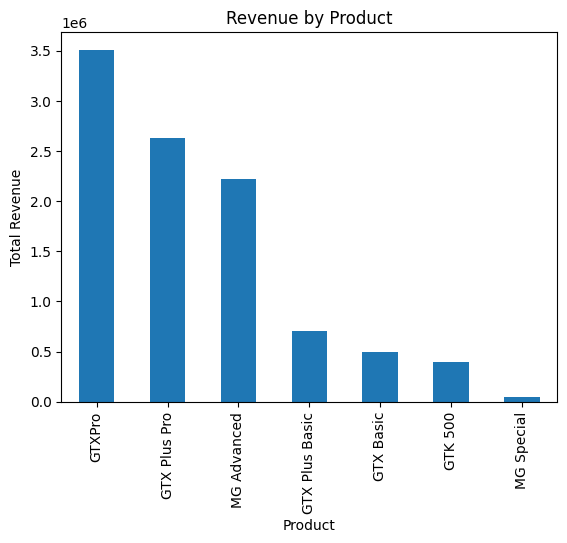

In [29]:
product_revenue.plot(kind="bar")

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.show()

In [30]:
df["sales_agent"].unique()

array(['Moses Frase', 'Darcel Schlecht', 'Zane Levy', 'Anna Snelling',
       'Vicki Laflamme', 'Markita Hansen', 'Niesha Huffines',
       'James Ascencio', 'Gladys Colclough', 'Maureen Marcano',
       'Hayden Neloms', 'Rosalina Dieter', 'Versie Hillebrand',
       'Daniell Hammack', 'Elease Gluck', 'Violet Mclelland',
       'Kami Bicknell', 'Rosie Papadopoulos', 'Kary Hendrixson',
       'Reed Clapper', 'Wilburn Farren', 'Garret Kinder',
       'Marty Freudenburg', 'Cassey Cress', 'Lajuana Vencill',
       'Boris Faz', 'Donn Cantrell', 'Corliss Cosme', 'Cecily Lampkin',
       'Jonathan Berthelot'], dtype=object)

In [31]:
df["sales_agent"].value_counts()


sales_agent
Darcel Schlecht       747
Vicki Laflamme        451
Anna Snelling         448
Kary Hendrixson       438
Kami Bicknell         362
Versie Hillebrand     361
Zane Levy             349
Cassey Cress          346
Jonathan Berthelot    345
Gladys Colclough      317
Lajuana Vencill       311
Corliss Cosme         310
Markita Hansen        306
Maureen Marcano       285
Marty Freudenburg     281
Donn Cantrell         275
James Ascencio        267
Violet Mclelland      261
Moses Frase           260
Daniell Hammack       259
Niesha Huffines       239
Reed Clapper          237
Boris Faz             210
Cecily Lampkin        203
Hayden Neloms         202
Elease Gluck          177
Rosie Papadopoulos    160
Rosalina Dieter       160
Garret Kinder         123
Wilburn Farren        110
Name: count, dtype: int64

In [32]:
agent_revenue = won.groupby("sales_agent")["close_value"].sum()

print(agent_revenue)

sales_agent
Anna Snelling          275056.0
Boris Faz              261631.0
Cassey Cress           450489.0
Cecily Lampkin         229800.0
Corliss Cosme          421036.0
Daniell Hammack        364229.0
Darcel Schlecht       1153214.0
Donn Cantrell          445860.0
Elease Gluck           289195.0
Garret Kinder          197773.0
Gladys Colclough       345674.0
Hayden Neloms          272111.0
James Ascencio         413533.0
Jonathan Berthelot     284886.0
Kami Bicknell          316456.0
Kary Hendrixson        454298.0
Lajuana Vencill        194632.0
Markita Hansen         328792.0
Marty Freudenburg      291195.0
Maureen Marcano        350395.0
Moses Frase            207182.0
Niesha Huffines        176961.0
Reed Clapper           438336.0
Rosalina Dieter        235403.0
Rosie Papadopoulos     230169.0
Versie Hillebrand      187693.0
Vicki Laflamme         478396.0
Violet Mclelland       123431.0
Wilburn Farren         157640.0
Zane Levy              430068.0
Name: close_value, dtype: fl

In [33]:
agent_revenue = agent_revenue.sort_values(ascending=False)

print(agent_revenue)

sales_agent
Darcel Schlecht       1153214.0
Vicki Laflamme         478396.0
Kary Hendrixson        454298.0
Cassey Cress           450489.0
Donn Cantrell          445860.0
Reed Clapper           438336.0
Zane Levy              430068.0
Corliss Cosme          421036.0
James Ascencio         413533.0
Daniell Hammack        364229.0
Maureen Marcano        350395.0
Gladys Colclough       345674.0
Markita Hansen         328792.0
Kami Bicknell          316456.0
Marty Freudenburg      291195.0
Elease Gluck           289195.0
Jonathan Berthelot     284886.0
Anna Snelling          275056.0
Hayden Neloms          272111.0
Boris Faz              261631.0
Rosalina Dieter        235403.0
Rosie Papadopoulos     230169.0
Cecily Lampkin         229800.0
Moses Frase            207182.0
Garret Kinder          197773.0
Lajuana Vencill        194632.0
Versie Hillebrand      187693.0
Niesha Huffines        176961.0
Wilburn Farren         157640.0
Violet Mclelland       123431.0
Name: close_value, dtype: fl

In [34]:
print("Top Sales Agent:", agent_revenue.idxmax())

Top Sales Agent: Darcel Schlecht


In [35]:
print("Highest Agent Revenue:", agent_revenue.max())

Highest Agent Revenue: 1153214.0


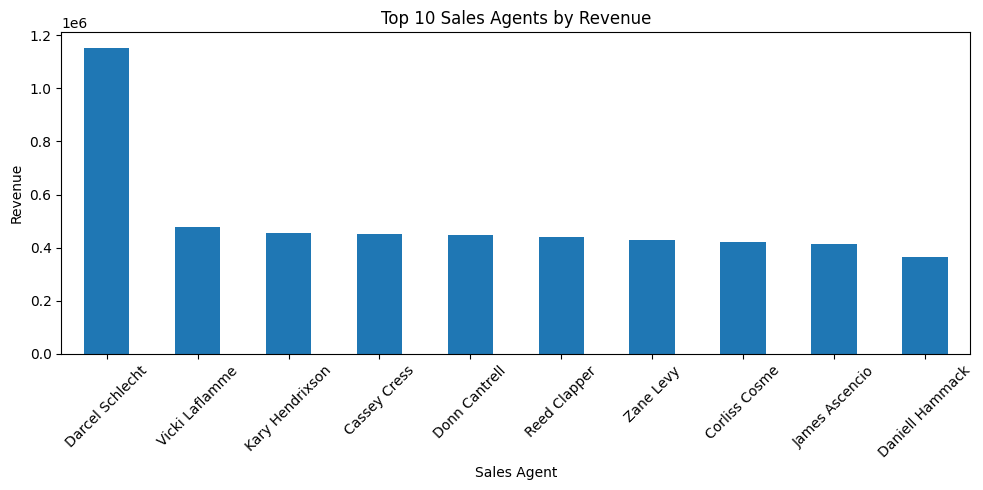

In [36]:
top_agents = agent_revenue.head(10)

top_agents.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Sales Agents by Revenue")
plt.xlabel("Sales Agent")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
closed_data = df[
    (df["deal_stage"] == "Won") |
    (df["deal_stage"] == "Lost")
]

In [38]:
agent_won = closed_data[closed_data["deal_stage"] == "Won"].groupby("sales_agent").size()

print(agent_won)

sales_agent
Anna Snelling         208
Boris Faz             101
Cassey Cress          163
Cecily Lampkin        107
Corliss Cosme         150
Daniell Hammack       114
Darcel Schlecht       349
Donn Cantrell         158
Elease Gluck           80
Garret Kinder          75
Gladys Colclough      135
Hayden Neloms         107
James Ascencio        135
Jonathan Berthelot    171
Kami Bicknell         174
Kary Hendrixson       209
Lajuana Vencill       127
Markita Hansen        130
Marty Freudenburg     122
Maureen Marcano       149
Moses Frase           129
Niesha Huffines       105
Reed Clapper          155
Rosalina Dieter        72
Rosie Papadopoulos     78
Versie Hillebrand     176
Vicki Laflamme        221
Violet Mclelland      122
Wilburn Farren         55
Zane Levy             161
dtype: int64


In [39]:
agent_total = closed_data.groupby("sales_agent").size()

print(agent_total)

sales_agent
Anna Snelling         336
Boris Faz             153
Cassey Cress          261
Cecily Lampkin        160
Corliss Cosme         229
Daniell Hammack       187
Darcel Schlecht       553
Donn Cantrell         275
Elease Gluck          126
Garret Kinder         123
Gladys Colclough      232
Hayden Neloms         152
James Ascencio        206
Jonathan Berthelot    264
Kami Bicknell         272
Kary Hendrixson       335
Lajuana Vencill       231
Markita Hansen        227
Marty Freudenburg     194
Maureen Marcano       213
Moses Frase           195
Niesha Huffines       175
Reed Clapper          237
Rosalina Dieter       110
Rosie Papadopoulos    121
Versie Hillebrand     264
Vicki Laflamme        347
Violet Mclelland      193
Wilburn Farren         79
Zane Levy             261
dtype: int64


In [40]:
agent_win_rate = agent_won / agent_total * 100

print(agent_win_rate.round(2))

sales_agent
Anna Snelling         61.90
Boris Faz             66.01
Cassey Cress          62.45
Cecily Lampkin        66.88
Corliss Cosme         65.50
Daniell Hammack       60.96
Darcel Schlecht       63.11
Donn Cantrell         57.45
Elease Gluck          63.49
Garret Kinder         60.98
Gladys Colclough      58.19
Hayden Neloms         70.39
James Ascencio        65.53
Jonathan Berthelot    64.77
Kami Bicknell         63.97
Kary Hendrixson       62.39
Lajuana Vencill       54.98
Markita Hansen        57.27
Marty Freudenburg     62.89
Maureen Marcano       69.95
Moses Frase           66.15
Niesha Huffines       60.00
Reed Clapper          65.40
Rosalina Dieter       65.45
Rosie Papadopoulos    64.46
Versie Hillebrand     66.67
Vicki Laflamme        63.69
Violet Mclelland      63.21
Wilburn Farren        69.62
Zane Levy             61.69
dtype: float64


In [41]:
stage_count = df["deal_stage"].value_counts()

print(stage_count)

deal_stage
Won            4238
Lost           2473
Engaging       1589
Prospecting     500
Name: count, dtype: int64


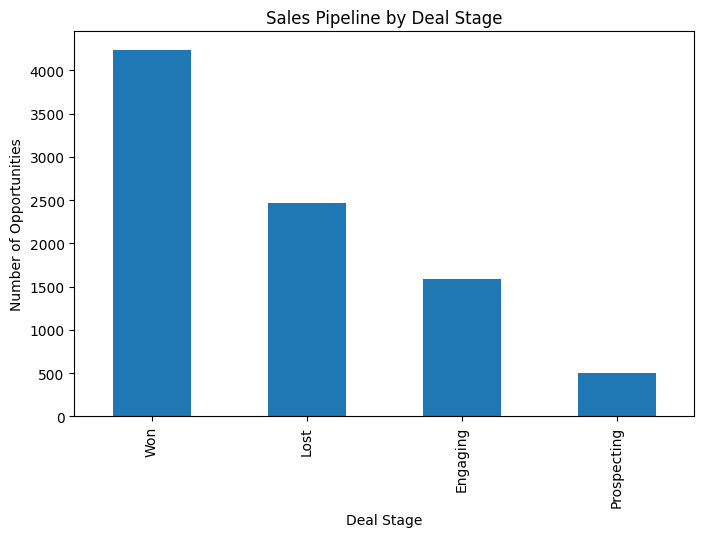

In [42]:
stage_count.plot(kind="bar", figsize=(8, 5))

plt.title("Sales Pipeline by Deal Stage")
plt.xlabel("Deal Stage")
plt.ylabel("Number of Opportunities")
plt.show()

In [43]:
open_deals = df[
    (df["deal_stage"] == "Engaging") |
    (df["deal_stage"] == "Prospecting")
]

print("Open Opportunities:", len(open_deals))

Open Opportunities: 2089


In [44]:
print(open_deals["deal_stage"].value_counts())

deal_stage
Engaging       1589
Prospecting     500
Name: count, dtype: int64


In [45]:
open_percentage = len(open_deals) / len(df) * 100

print("Open Opportunities Percentage:", round(open_percentage, 2), "%")

Open Opportunities Percentage: 23.74 %


In [46]:
won_dates = df[
    (df["deal_stage"] == "Won") &
    (df["engage_date"].notnull()) &
    (df["close_date"].notnull())
]

In [47]:
won_dates["days_to_close"] = (
    won_dates["close_date"] - won_dates["engage_date"]
).dt.days

/var/folders/xj/wyw5193s2053p8c1ns9xg3f80000gn/T/ipykernel_3243/2900736386.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  won_dates["days_to_close"] = (


In [48]:
won_dates = won_dates.copy()

won_dates["days_to_close"] = (
    won_dates["close_date"] - won_dates["engage_date"]
).dt.days

average_days = won_dates["days_to_close"].mean()

print("Average Days to Close:", round(average_days, 2))

Average Days to Close: 51.78


In [49]:
print("Total Opportunities:", len(df))
print("Won Deals:", len(won))
print("Lost Deals:", len(lost))
print("Win Rate:", round(win_rate, 2), "%")
print("Total Revenue:", total_revenue)
print("Average Deal Value:", round(average, 2))
print("Average Days to Close:", round(average_days, 2))

Total Opportunities: 8800
Won Deals: 4238
Lost Deals: 2473
Win Rate: 63.15 %
Total Revenue: 10005534.0
Average Deal Value: 2360.91
Average Days to Close: 51.78


In [50]:
summary = pd.DataFrame({
    "Metric": [
        "Total Opportunities",
        "Won Deals",
        "Lost Deals",
        "Closed Deals",
        "Open Opportunities",
        "Win Rate (%)",
        "Total Won Revenue",
        "Average Deal Value",
        "Average Days to Close"
    ],
    "Value": [
        len(df),
        len(won),
        len(lost),
        closed,
        len(open_deals),
        round(win_rate, 2),
        total_revenue,
        round(average, 2),
        round(average_days, 2)
    ]
})

summary

,Metric,Value
0,Total Opportunities,8800.00
1,Won Deals,4238.00
2,Lost Deals,2473.00
3,Closed Deals,6711.00
4,Open Opportunities,2089.00
5,Win Rate (%),63.15
6,Total Won Revenue,10005534.00
7,Average Deal Value,2360.91
8,Average Days to Close,51.78


In [51]:
summary.to_excel("B2B_Business_Summary.xlsx", index=False)

In [52]:
product_revenue.to_csv("Product_Revenue.csv")

agent_revenue.to_csv("Agent_Revenue.csv")

In [53]:
stage_count.to_csv("Pipeline_Analysis.csv")

In [54]:
agent_win_rate.to_csv("Agent_Win_Rate.csv")

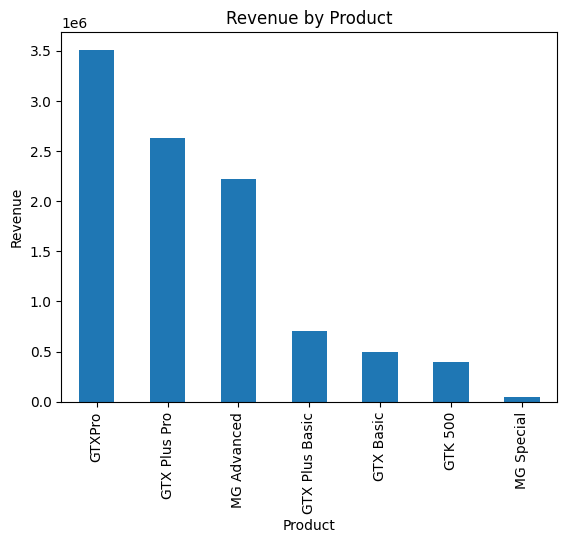

In [55]:
product_revenue.plot(kind="bar")

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")

plt.savefig("Product_Revenue.png")
plt.show()

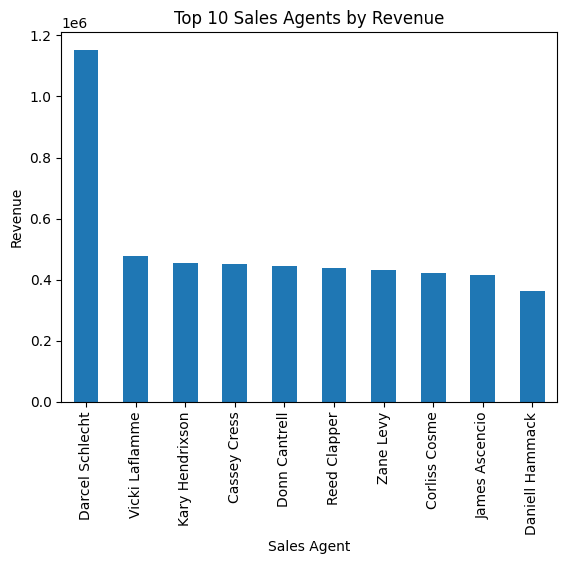

In [56]:
top_agents.plot(kind="bar")

plt.title("Top 10 Sales Agents by Revenue")
plt.xlabel("Sales Agent")
plt.ylabel("Revenue")

plt.savefig("Agent_Revenue.png")
plt.show()

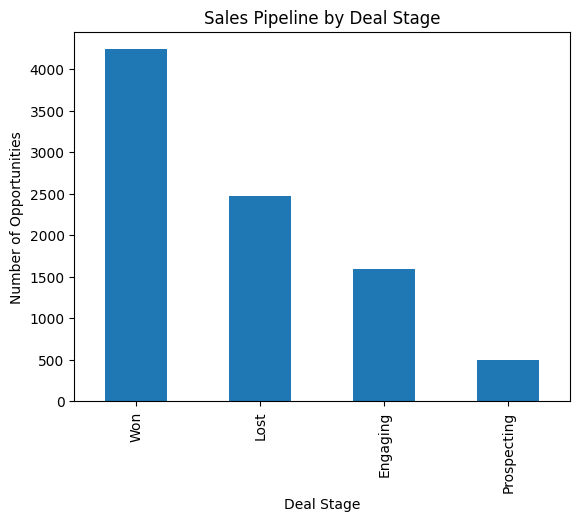

In [57]:
stage_count.plot(kind="bar")

plt.title("Sales Pipeline by Deal Stage")
plt.xlabel("Deal Stage")
plt.ylabel("Number of Opportunities")

plt.savefig("Sales_Pipeline.png")
plt.show()

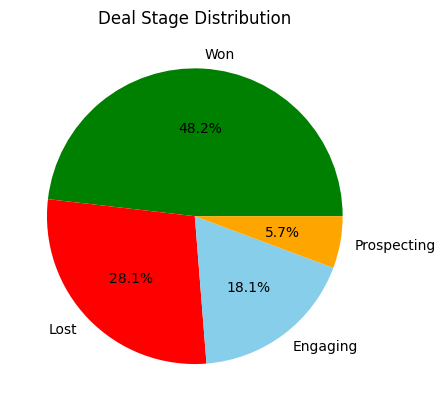

In [58]:
colors = ["green", "red", "skyblue", "orange"]

stage_count.plot(kind="pie", autopct="%1.1f%%", colors=colors)

plt.title("Deal Stage Distribution")
plt.ylabel("")
plt.show()

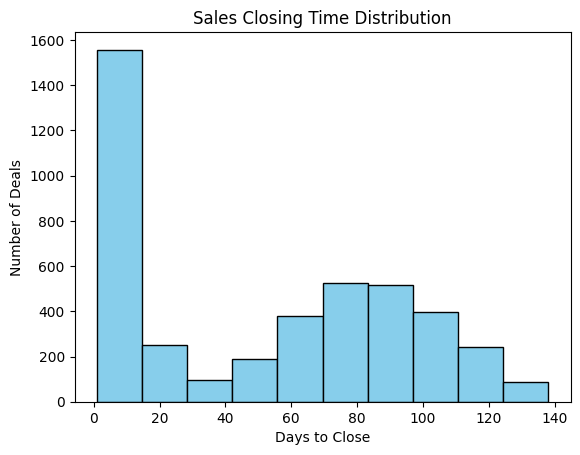

In [59]:
plt.hist(won_dates["days_to_close"], bins=10, color="skyblue", edgecolor="black")

plt.title("Sales Closing Time Distribution")
plt.xlabel("Days to Close")
plt.ylabel("Number of Deals")

plt.show()

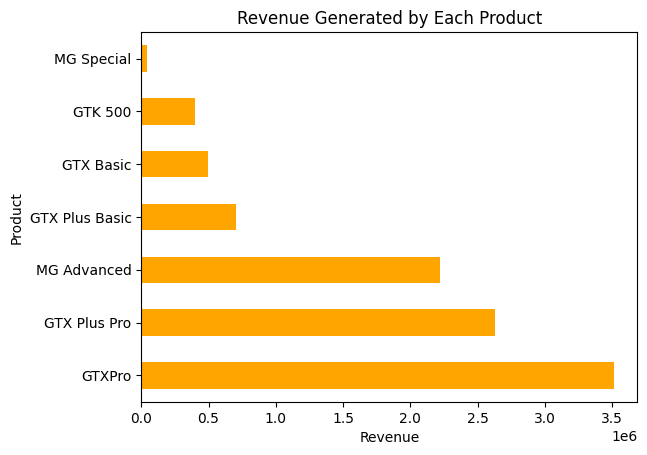

In [60]:
product_revenue.plot(kind="barh", color="orange")

plt.title("Revenue Generated by Each Product")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.show()

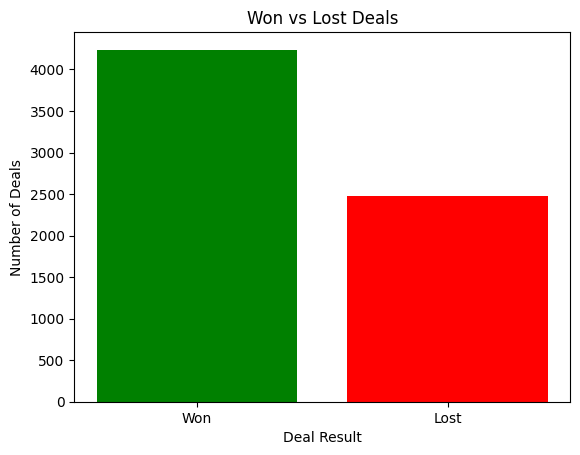

In [61]:
deal_result = [len(won), len(lost)]

labels = ["Won", "Lost"]

plt.bar(labels, deal_result, color=["green", "red"])

plt.title("Won vs Lost Deals")
plt.xlabel("Deal Result")
plt.ylabel("Number of Deals")

plt.show()